In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
# Determine project root
current_directory = Path.cwd()

if (current_directory / "data" / "raw" / "used_cars.csv").exists():
    PROJECT_ROOT = current_directory
else:
    PROJECT_ROOT = current_directory.parent

# Dataset path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "used_cars.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully!
Dataset shape: (8128, 13)


In [13]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [14]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [15]:
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [16]:
df.describe(include="all")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
count,8128,8128.000000,8.128000e+03,8.128000e+03,8128,8128,8128,8128,7907,7907,7913,7906,7907.000000
unique,2058,NaN,NaN,NaN,4,3,2,5,393,121,322,441,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,NaN
freq,129,NaN,NaN,NaN,4402,6766,7078,5289,225,1017,377,530,NaN
mean,NaN,2013.804011,6.382718e+05,6.981951e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.416719
std,NaN,4.044249,8.062534e+05,5.655055e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.959588
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,NaN,2011.000000,2.549990e+05,3.500000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.800000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


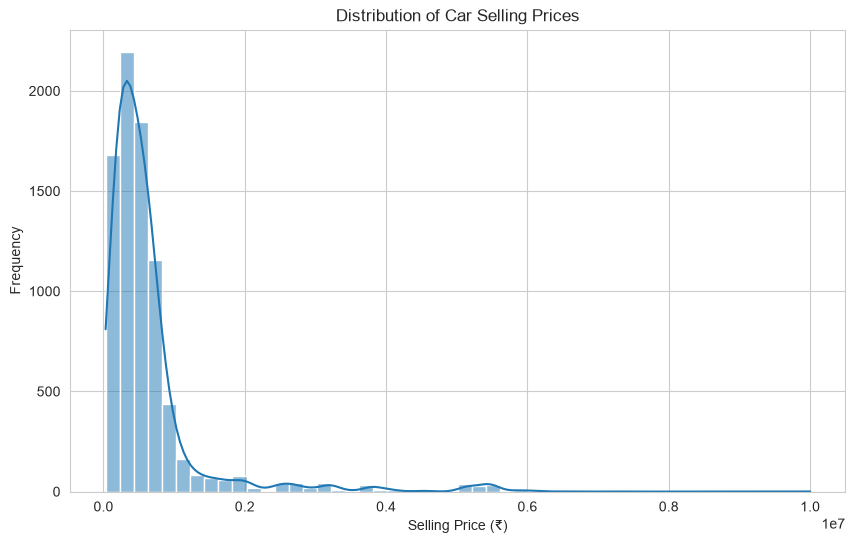

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="selling_price",
    bins=50,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Frequency")

plt.show()

### Histogram Interpretation

The selling_price distribution is heavily right-skewed.
Most vehicles are concentrated within lower price ranges,
while a small number of expensive vehicles create a long
tail towards higher prices.

The mean selling price is higher than the median,
indicating that expensive vehicles influence the overall
price distribution.

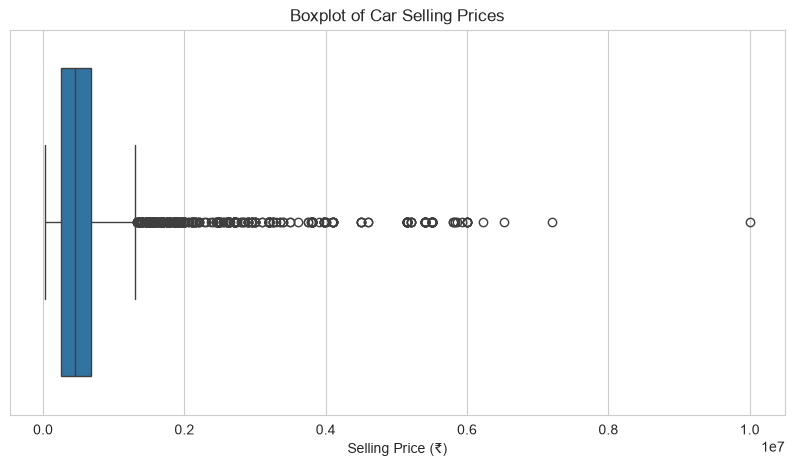

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["selling_price"])

plt.title("Boxplot of Car Selling Prices")
plt.xlabel("Selling Price (₹)")

plt.show()

### Boxplot Interpretation

The boxplot identifies numerous potential upper-end outliers.
The dataset contains vehicles with selling prices reaching
₹10,000,000.

These observations are potential outliers based on the
boxplot's statistical criteria, but they are not necessarily
incorrect records. Further investigation is required before
removing any observations.

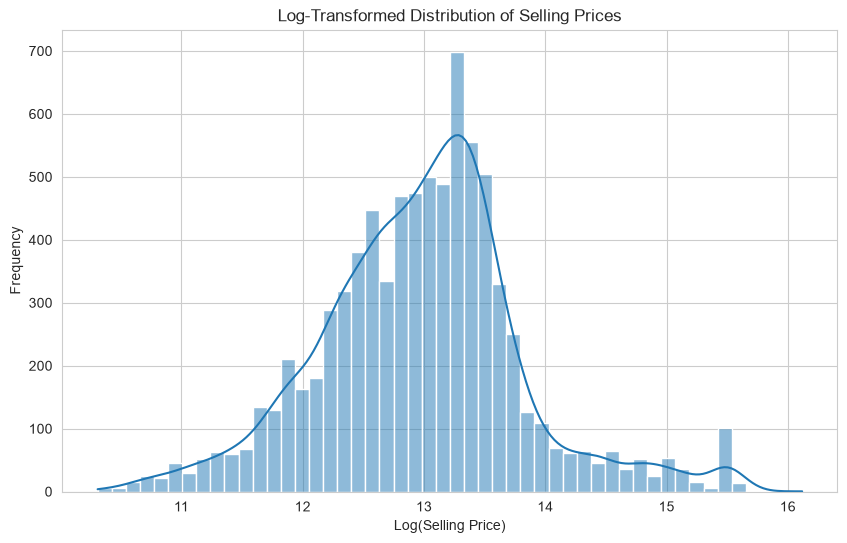

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    np.log1p(df["selling_price"]),
    bins=50,
    kde=True
)

plt.title("Log-Transformed Distribution of Selling Prices")
plt.xlabel("Log(Selling Price)")
plt.ylabel("Frequency")

plt.show()

### Log Transformation Analysis

The original selling_price distribution was heavily right-skewed.
Applying the logarithmic transformation using np.log1p() reduced
the skewness and produced a more balanced distribution.

The transformation compresses extreme selling prices while
preserving the relative ordering of observations.

Although the transformed distribution is more balanced, it is
not perfectly normal. This transformation may be useful during
model development and will be evaluated further.

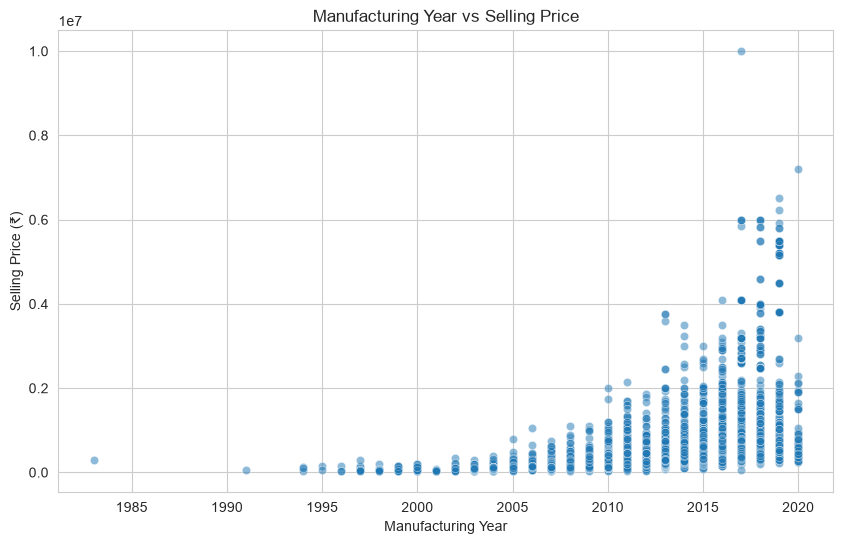

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="year",
    y="selling_price",
    alpha=0.5
)

plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (₹)")

plt.show()

### Manufacturing Year vs Selling Price

The scatter plot indicates a strong positive relationship between
manufacturing year and selling price.

Vehicles manufactured in more recent years generally have higher
selling prices than older vehicles.

The price variation also increases among newer vehicles,
suggesting that other features such as brand, engine capacity,
fuel type, and mileage influence selling price.

The relationship is not perfectly linear, indicating that
manufacturing year alone is insufficient to predict a vehicle's
selling price accurately.

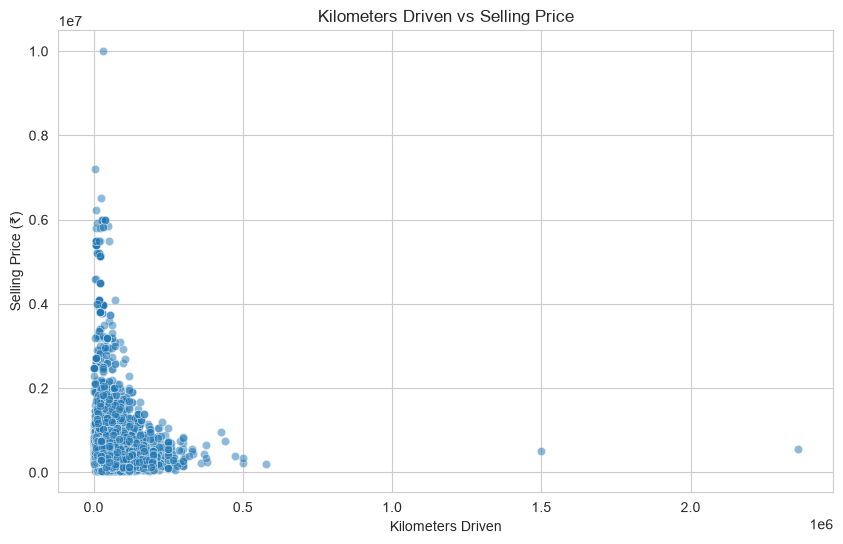

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (₹)")

plt.show()

### Kilometers Driven vs Selling Price

The scatter plot indicates a generally negative relationship
between kilometers driven and selling price.

Vehicles driven fewer kilometers generally have higher selling
prices and exhibit a wider range of prices.

As kilometers driven increases, selling prices tend to decrease.
However, this relationship is not perfectly linear because
vehicle age, brand, fuel type, and other characteristics also
influence selling price.

The dataset also contains extreme kilometer-driven values,
including observations exceeding one million kilometers.
These values require further investigation during data cleaning.

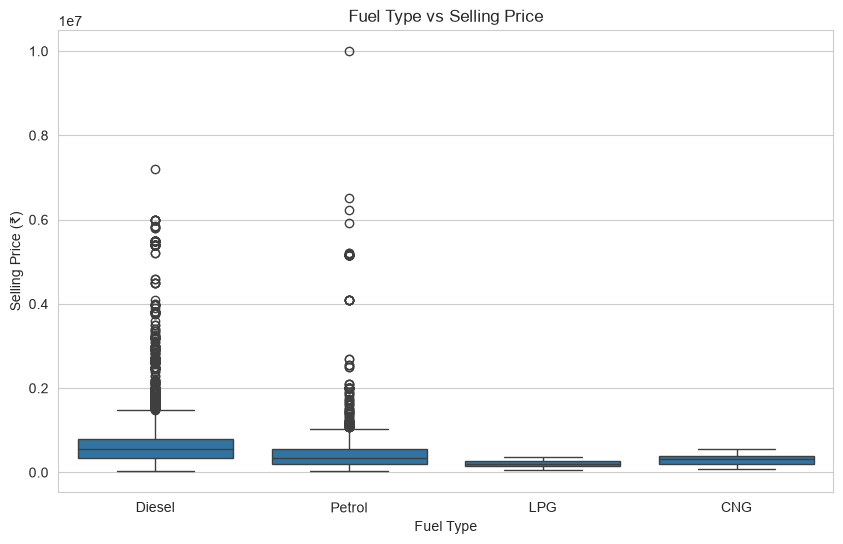

In [22]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="fuel",
    y="selling_price"
)

plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹)")

plt.show()

### Fuel Type vs Selling Price

The boxplot indicates differences in selling price across
fuel types.

Diesel vehicles exhibit a relatively higher median selling
price and a wider price distribution compared to petrol
vehicles.

Petrol vehicles also contain several high-priced outliers.
LPG and CNG vehicles generally exhibit comparatively lower
and more compact price distributions.

These observations suggest that fuel type may be an
important feature for predicting selling price.
However, differences in the number of observations across
fuel categories should also be considered.

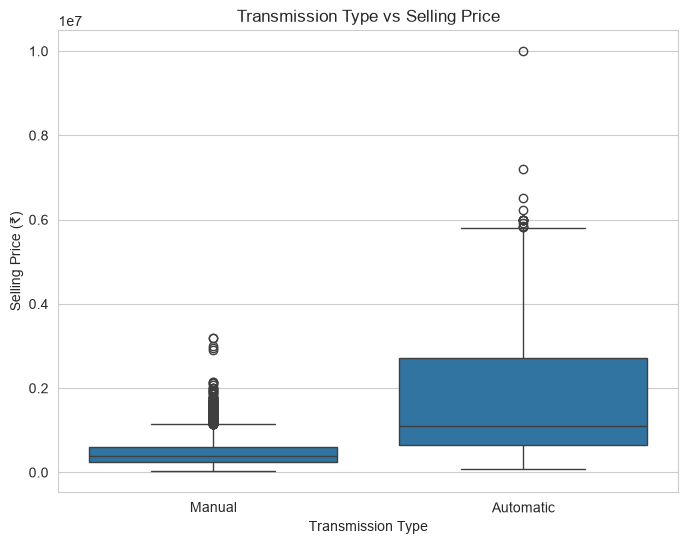

In [23]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="transmission",
    y="selling_price"
)

plt.title("Transmission Type vs Selling Price")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (₹)")

plt.show()

### Transmission Type vs Selling Price

The boxplot indicates that automatic transmission vehicles
have a substantially higher median selling price compared
to manual transmission vehicles.

Automatic vehicles also exhibit a wider price distribution
and greater variability in selling prices.

Manual vehicles are concentrated within comparatively
lower price ranges, although several high-priced outliers
are present.

Transmission type appears to be an important feature for
predicting selling price. However, this relationship may
also be influenced by vehicle age, brand, and other
characteristics.

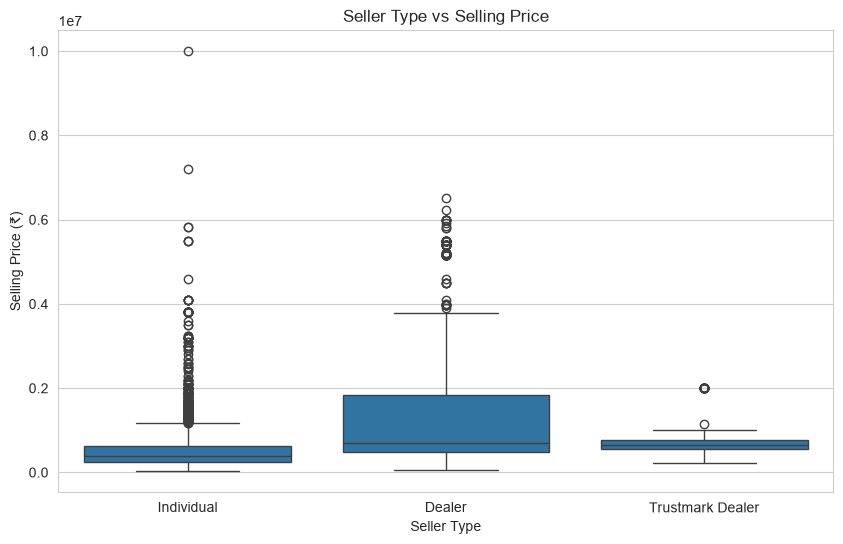

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="seller_type",
    y="selling_price"
)

plt.title("Seller Type vs Selling Price")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price (₹)")

plt.show()

### Seller Type vs Selling Price

The boxplot indicates differences in selling prices across
seller categories.

Dealer-sold vehicles exhibit a higher median selling price
and wider price distribution compared to individual sellers.

Individual sellers have a relatively lower median price,
although several high-priced outliers are present.

Trustmark dealer vehicles exhibit a comparatively compact
price distribution.

Seller type may be a useful feature for predicting selling
price, although these differences may also be influenced
by vehicle characteristics.

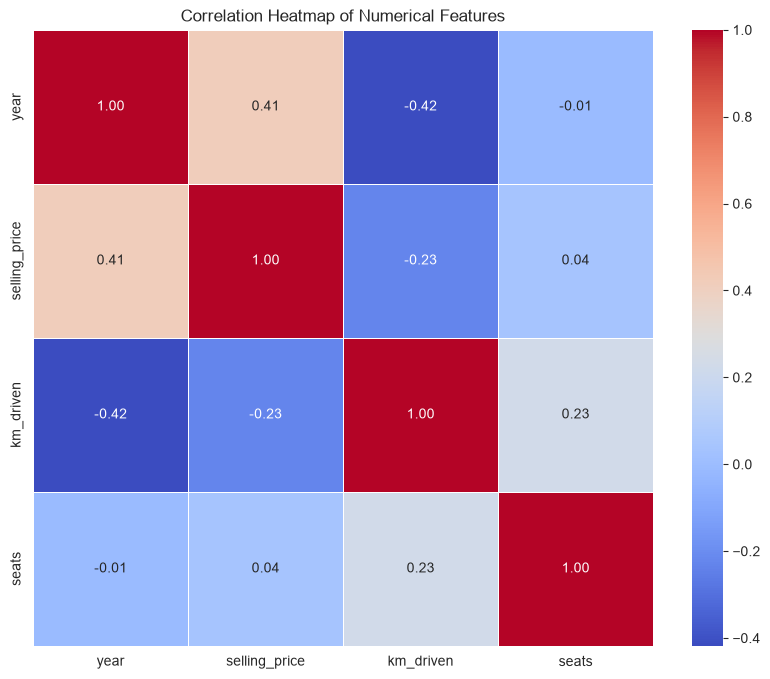

In [25]:
# Select numerical columns
numerical_columns = [
    "year",
    "selling_price",
    "km_driven",
    "seats"
]

# Calculate correlation matrix
correlation_matrix = df[numerical_columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

### Numerical Feature Correlation Analysis

The correlation heatmap shows a moderate positive correlation
between manufacturing year and selling price (0.41).

Kilometers driven exhibits a weak negative correlation with
selling price (-0.23), indicating that vehicles driven
more kilometers generally tend to have lower selling prices.

Seats show almost no linear correlation with selling price
(0.04).

Manufacturing year and kilometers driven have a moderate
negative correlation (-0.42), suggesting that newer
vehicles generally have fewer kilometers driven.

These results indicate that numerical correlations alone
cannot fully explain selling price. Categorical features
and nonlinear relationships may also play important roles
in prediction.

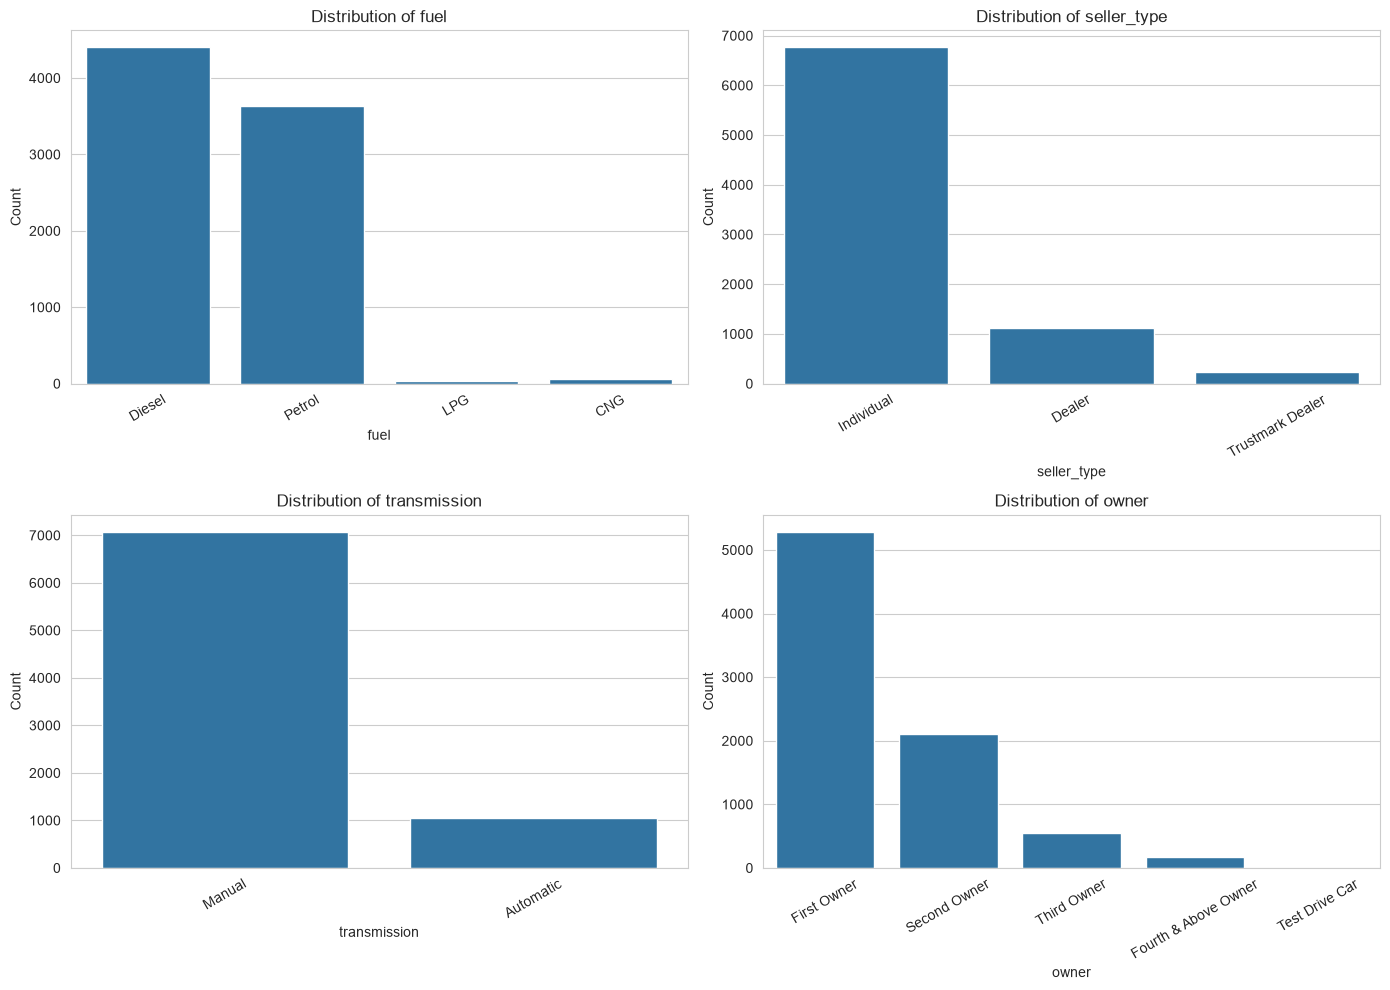

In [26]:
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, axis in zip(categorical_columns, axes.flatten()):
    sns.countplot(
        data=df,
        x=column,
        ax=axis
    )

    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
    axis.set_ylabel("Count")
    axis.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

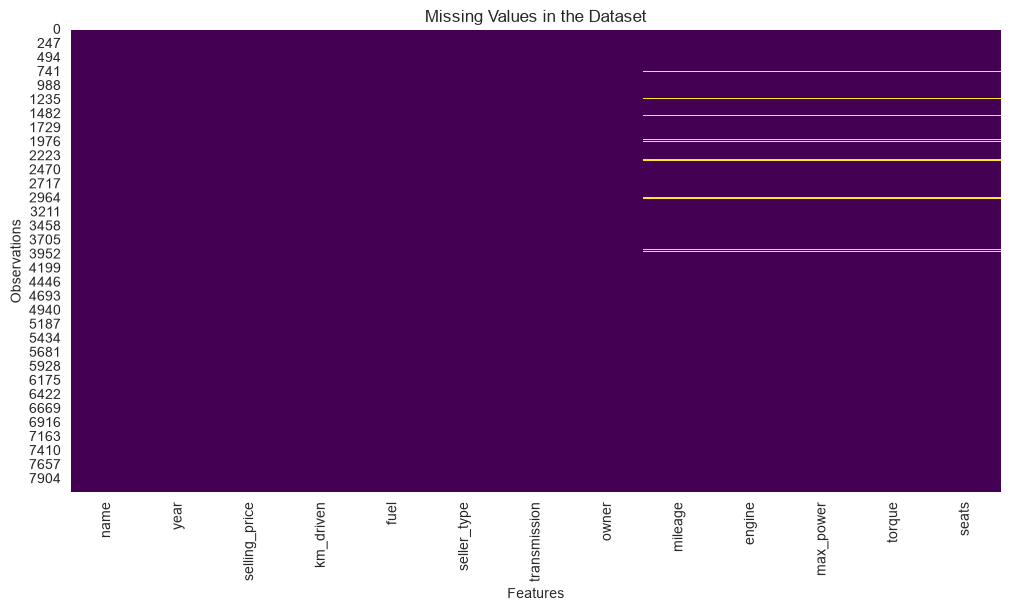

In [27]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in the Dataset")
plt.xlabel("Features")
plt.ylabel("Observations")

plt.show()

In [28]:
numerical_columns = [
    "selling_price",
    "km_driven",
    "year",
    "seats"
]

outlier_summary = {}

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary[column] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    }

outlier_summary_df = pd.DataFrame(outlier_summary).T

outlier_summary_df

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
selling_price,254999.0,675000.0,420001.0,-375002.5,1305001.5,600.0,7.38
km_driven,35000.0,98000.0,63000.0,-59500.0,192500.0,170.0,2.09
year,2011.0,2017.0,6.0,2002.0,2026.0,81.0,1.00
seats,5.0,5.0,0.0,5.0,5.0,1653.0,20.34


# Exploratory Data Analysis (EDA) - Summary

## Dataset Overview
- Total records: 8,128
- Total features: 13
- Target variable: selling_price
- Duplicate records identified: 1,202
- Missing values identified in multiple features

## Target Variable
The selling_price distribution is heavily right-skewed.
The mean selling price is higher than the median,
indicating that expensive vehicles influence the overall
price distribution.

Logarithmic transformation reduced the skewness and
produced a more balanced distribution.

## Numerical Feature Relationships
- Manufacturing year exhibits a moderate positive
  correlation with selling price.
- Kilometers driven exhibits a weak negative
  correlation with selling price.
- Seats show almost no linear correlation with
  selling price.
- Manufacturing year and kilometers driven exhibit
  a moderate negative correlation.

## Categorical Feature Relationships
- Diesel vehicles generally exhibit higher selling
  prices than petrol vehicles.
- Automatic transmission vehicles have a substantially
  higher median selling price than manual vehicles.
- Dealer-sold vehicles generally exhibit higher
  selling prices than individual-sold vehicles.
- Fuel type, transmission, and seller type may be
  useful predictive features.

## Data Quality Issues Identified
- Duplicate records
- Missing values
- Numerical information stored as strings
- Potential outliers in selling_price and km_driven
- Inconsistent formatting in mileage, engine,
  max_power, and torque

## Conclusion
The dataset contains useful relationships between
vehicle characteristics and selling price.

However, data cleaning and feature engineering will
be necessary before model training.

The next phase will focus on handling duplicate
records, missing values, inconsistent data types,
numerical extraction, and potential outliers.